Image exists: True


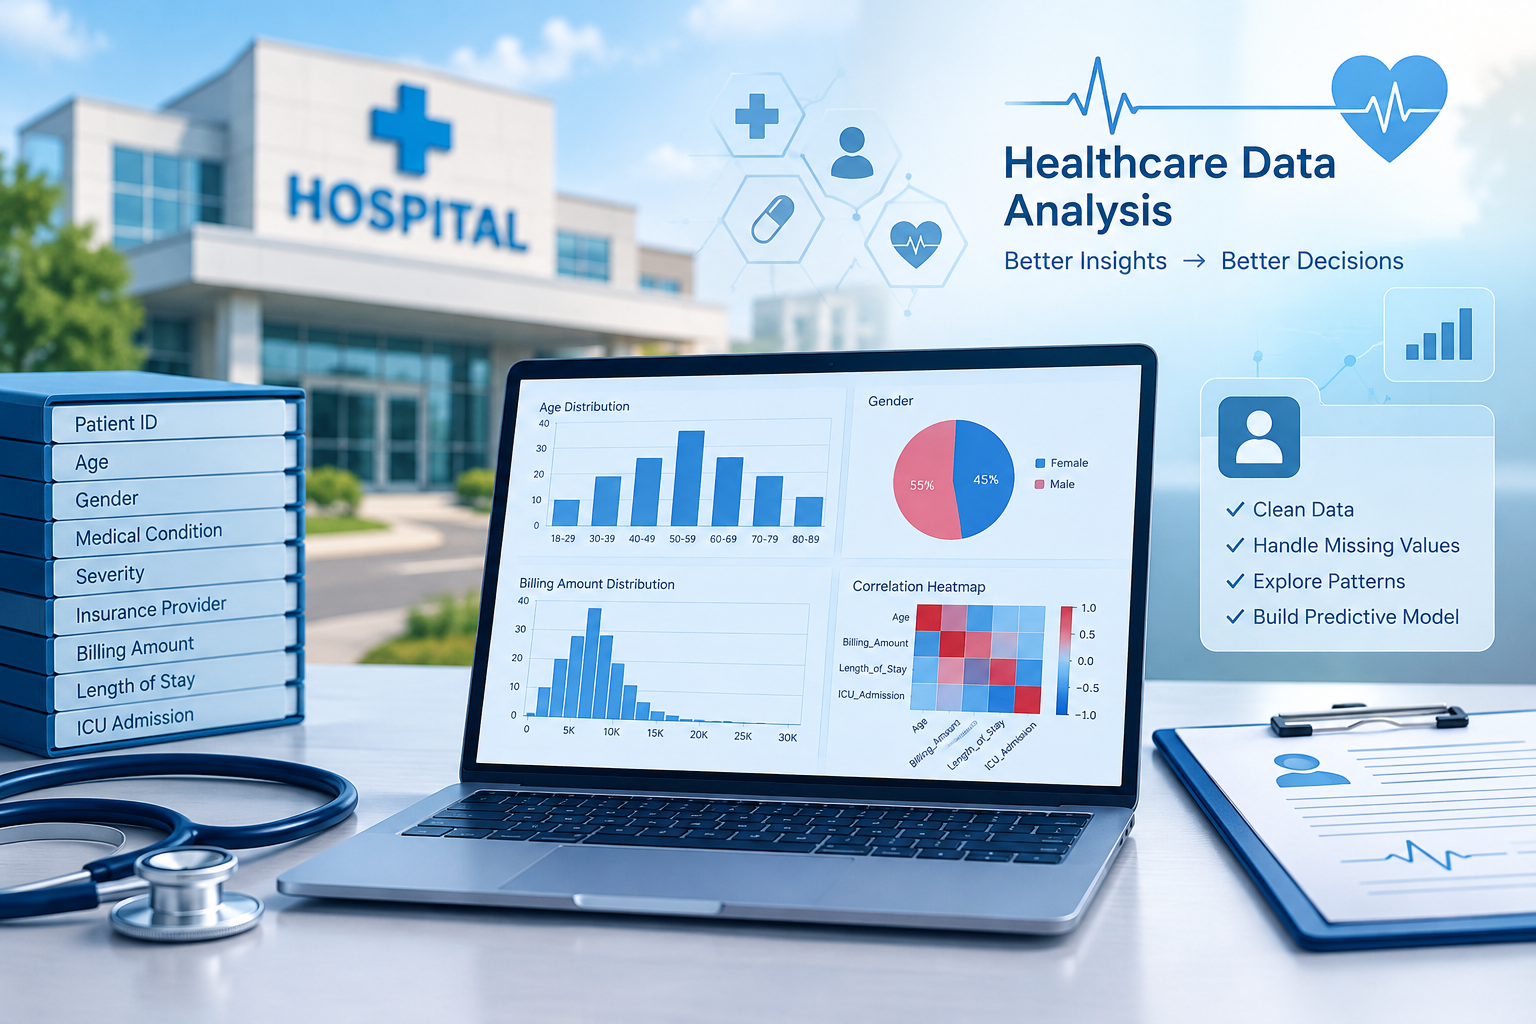

In [1]:
from IPython.display import display, Image
from pathlib import Path

image_path = Path(r"D:\small_hospital_\Healthcare Data Analysis Dashboard.png")

print("Image exists:", image_path.exists())

if image_path.exists():
    display(Image(filename=str(image_path)))
else:
    print("Image not found. Check the file name and folder.")

# 🏥 Hospital Dataset — Exploratory Data Analysis (EDA)

## 📌 Introduction

Exploratory Data Analysis (EDA) is an important step in the Machine Learning workflow. It helps us understand the dataset, identify missing values and outliers, explore feature distributions, and discover relationships between variables before building a predictive model.

## 🎯 Objectives

- Understand the structure and characteristics of the hospital dataset.
- Inspect data types, missing values, and duplicate records.
- Analyze numerical and categorical features.
- Visualize data distributions and identify potential outliers.
- Explore relationships between patient characteristics, medical conditions, billing amounts, length of stay, and ICU admission.
- Prepare insights to guide data preprocessing and Decision Tree model development.

## 📊 Dataset Overview

The dataset contains patient information, including demographic characteristics, medical conditions, severity levels, insurance providers, billing amounts, length of hospital stay, and ICU admission status.

**Dataset size:** 250 rows × 10 columns.

## 🛠️ Tools & Libraries

- Python
- Pandas & NumPy
- Matplotlib & Seaborn
- Scikit-learn (for the subsequent Machine Learning stage)

## 🔍 Analysis Workflow

1. Data Loading and Inspection
2. Data Quality Assessment
3. Univariate Analysis
4. Bivariate Analysis
5. Key Findings and Recommendations

**Note:** This notebook focuses on understanding and analyzing the data before proceeding to preprocessing and model training.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Everything is working!")

Everything is working!


In [9]:
import pandas as pd

df = pd.read_excel(r"D:\small_hospital_\small_hospital_ml_dataset.xlsx")

df.head()

,Patient_ID,Age,Gender,Blood_Type,Medical_Condition,Severity,Insurance_Provider,Billing_Amount_USD,ICU_Admission,Length_of_Stay_Days
0,PID-1000,69,Female,B+,Hypertension,Medium,Medicare,14122,0,6
1,PID-1001,32,Male,A-,Diabetes,Low,NaN,7262,0,3
2,PID-1002,89,Female,A+,Diabetes,Medium,Private,7423,0,4
3,PID-1003,78,Female,A+,Diabetes,Low,Private,3076,0,1
4,PID-1004,38,Female,A-,Asthma,Low,Medicaid,2548,0,1


In [10]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (250, 10)

Column Names:
['Patient_ID', 'Age', 'Gender', 'Blood_Type', 'Medical_Condition', 'Severity', 'Insurance_Provider', 'Billing_Amount_USD', 'ICU_Admission', 'Length_of_Stay_Days']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Patient_ID           250 non-null    str  
 1   Age                  250 non-null    int64
 2   Gender               250 non-null    str  
 3   Blood_Type           250 non-null    str  
 4   Medical_Condition    227 non-null    str  
 5   Severity             250 non-null    str  
 6   Insurance_Provider   227 non-null    str  
 7   Billing_Amount_USD   250 non-null    int64
 8   ICU_Admission        250 non-null    int64
 9   Length_of_Stay_Days  250 non-null    int64
dtypes: int64(4), str(6)
memory usage: 19.7 KB

First 5 Rows:


,Patient_ID,Age,Gender,Blood_Type,Medical_Condition,Severity,Insurance_Provider,Billing_Amount_USD,ICU_Admission,Length_of_Stay_Days
0,PID-1000,69,Female,B+,Hypertension,Medium,Medicare,14122,0,6
1,PID-1001,32,Male,A-,Diabetes,Low,NaN,7262,0,3
2,PID-1002,89,Female,A+,Diabetes,Medium,Private,7423,0,4
3,PID-1003,78,Female,A+,Diabetes,Low,Private,3076,0,1
4,PID-1004,38,Female,A-,Asthma,Low,Medicaid,2548,0,1


The dataset contains 250 patient records and 10 columns. It includes demographic information, medical conditions, severity levels, insurance providers, billing amounts, length of stay, and ICU admission status

In [11]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Patient_ID,250,250,PID-1000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,250.0,NaN,NaN,NaN,52.7,21.731707,18.0,34.0,52.0,71.75,89.0
Gender,250,2,Female,138,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Blood_Type,250,8,B+,36,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medical_Condition,227,5,Hypertension,63,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Severity,250,3,Low,108,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Insurance_Provider,227,3,Medicare,98,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Billing_Amount_USD,250.0,NaN,NaN,NaN,10046.424,6590.525732,2078.0,5091.75,7857.0,14105.5,31186.0
ICU_Admission,250.0,NaN,NaN,NaN,0.136,0.343476,0.0,0.0,0.0,0.0,1.0
Length_of_Stay_Days,250.0,NaN,NaN,NaN,4.872,3.426746,1.0,2.0,3.0,7.0,14.0


Missing values are present in Medical_Condition and Insurance_Provider, with 23 missing values in each column. These values should be investigated before preprocessing.

In [12]:
display(
    df[df["Medical_Condition"].isna()]
    ["Severity"]
    .value_counts(dropna=False)
)

Severity
Low    23
Name: count, dtype: int64

In [13]:
print("Duplicate Rows:", df.duplicated().sum())

print("Duplicate Patient IDs:", df["Patient_ID"].duplicated().sum())

Duplicate Rows: 0
Duplicate Patient IDs: 0


No duplicate rows or duplicate Patient_ID values were found.

In [14]:
display(pd.DataFrame({
    "Data_Type": df.dtypes.astype(str),
    "Unique_Values": df.nunique(),
    "Missing_Values": df.isnull().sum()
}))

,Data_Type,Unique_Values,Missing_Values
Patient_ID,str,250,0
Age,int64,70,0
Gender,str,2,0
Blood_Type,str,8,0
Medical_Condition,str,5,23
Severity,str,3,0
Insurance_Provider,str,3,23
Billing_Amount_USD,int64,248,0
ICU_Admission,int64,2,0
Length_of_Stay_Days,int64,14,0


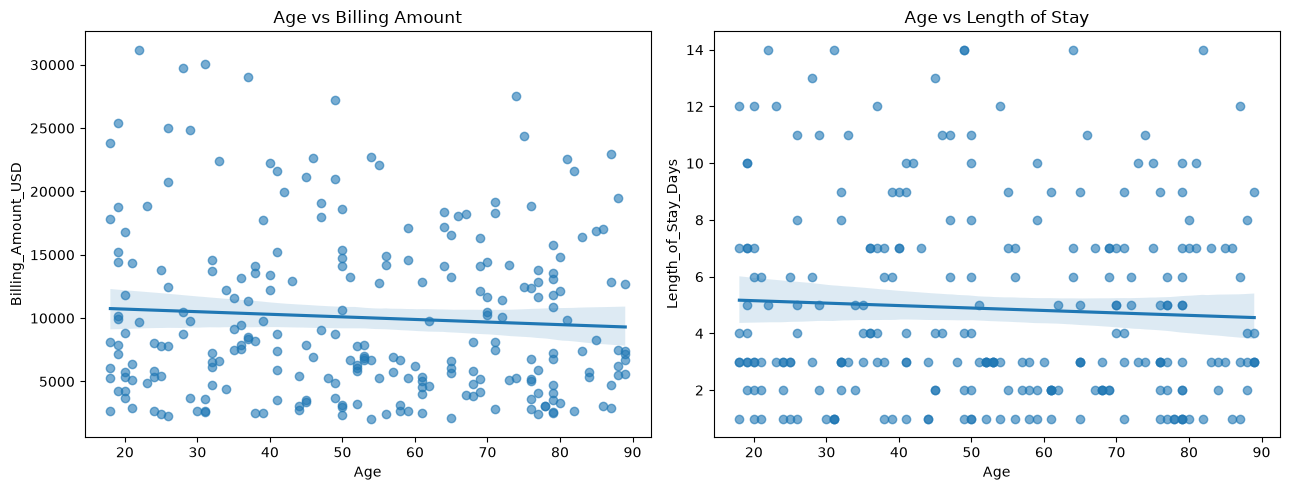

                      Age  Billing_Amount_USD  Length_of_Stay_Days
Age                  1.00               -0.07                -0.05
Billing_Amount_USD  -0.07                1.00                 0.94
Length_of_Stay_Days -0.05                0.94                 1.00


In [21]:


fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.regplot(
    data=df,
    x='Age',
    y='Billing_Amount_USD',
    ax=axes[0],
    scatter_kws={'alpha': 0.6}
)
axes[0].set_title('Age vs Billing Amount')

sns.regplot(
    data=df,
    x='Age',
    y='Length_of_Stay_Days',
    ax=axes[1],
    scatter_kws={'alpha': 0.6}
)
axes[1].set_title('Age vs Length of Stay')

plt.tight_layout()
plt.show()

print(df[['Age', 'Billing_Amount_USD',
          'Length_of_Stay_Days']].corr().round(2))

Scatter plots were used to investigate the relationships between age, billing amount, and length of stay. The correlation coefficients help identify the strength and direction of linear relationships. Correlation does not imply causation

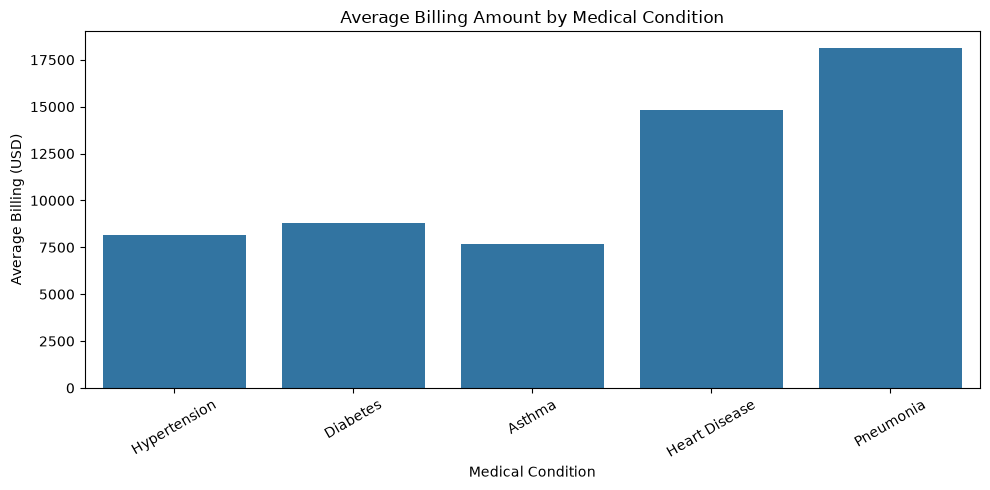

In [22]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x='Medical_Condition',
    y='Billing_Amount_USD',
    estimator='mean',
    errorbar=None
)

plt.title('Average Billing Amount by Medical Condition')
plt.xlabel('Medical Condition')
plt.ylabel('Average Billing (USD)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

The analysis compares average billing amounts across medical conditions. Differences may reflect variations in treatment requirements and length of stay, but the observed data alone cannot establish the reasons for these differences

ICU_Admission,No (%),Yes (%)
Severity,,
High,38.18,61.82
Low,100.00,0.00
Medium,100.00,0.00


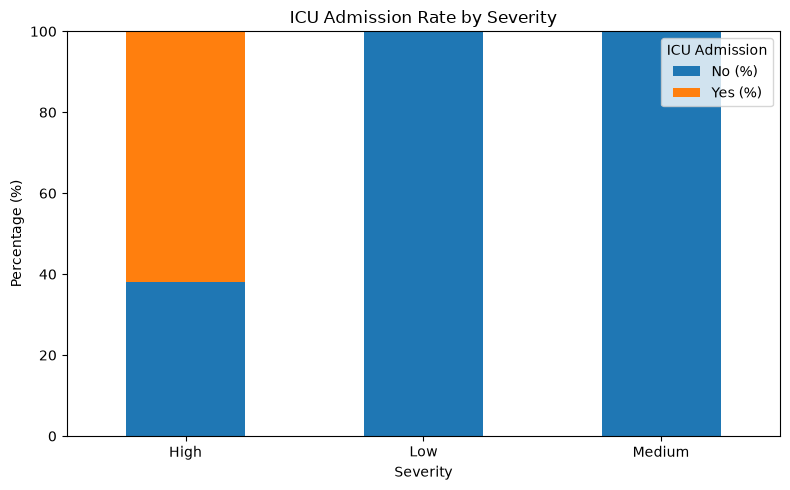

In [23]:

severity_icu = pd.crosstab(
    df['Severity'],
    df['ICU_Admission'],
    normalize='index'
) * 100

severity_icu = severity_icu.rename(
    columns={0: 'No (%)', 1: 'Yes (%)'}
)

display(severity_icu.round(2))

severity_icu.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5)
)

plt.title('ICU Admission Rate by Severity')
plt.xlabel('Severity')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='ICU Admission')
plt.tight_layout()
plt.show()

ICU admission rates were compared across severity levels. A higher admission rate among high-severity patients would indicate an association between severity and ICU admission in this datas

In [24]:


df['Age_Group'] = pd.cut(
    df['Age'],
    bins=[0, 18, 35, 50, 65, 100],
    labels=['Under 18', '18-35', '36-50', '51-65', 'Above 65'],
    right=True
)

age_stats = df.groupby(
    'Age_Group', observed=False
).agg(
    Patient_Count=('Patient_ID', 'count'),
    Average_Billing=('Billing_Amount_USD', 'mean'),
    Average_Stay=('Length_of_Stay_Days', 'mean'),
    ICU_Rate=('ICU_Admission', 'mean')
)

age_stats['ICU_Rate'] = age_stats['ICU_Rate'] * 100

display(age_stats.round(2))

,Patient_Count,Average_Billing,Average_Stay,ICU_Rate
Age_Group,,,,
Under 18,6,10634.00,5.00,16.67
18-35,61,10471.48,4.93,14.75
36-50,52,11203.62,5.73,21.15
51-65,47,8530.66,4.09,12.77
Above 65,84,9827.54,4.73,8.33


Patients were grouped by age to compare billing amounts, length of stay, and ICU admission rates across age categories. These comparisons help identify patterns that may not be apparent when analyzing age as a continuous variable

,Patient_Count,Average_Billing,Median_Billing,Average_Stay
Insurance_Provider,,,,
Medicaid,38,9827.87,7039.5,4.61
Medicare,98,10120.03,8431.0,4.89
Private,91,9445.69,7440.0,4.66


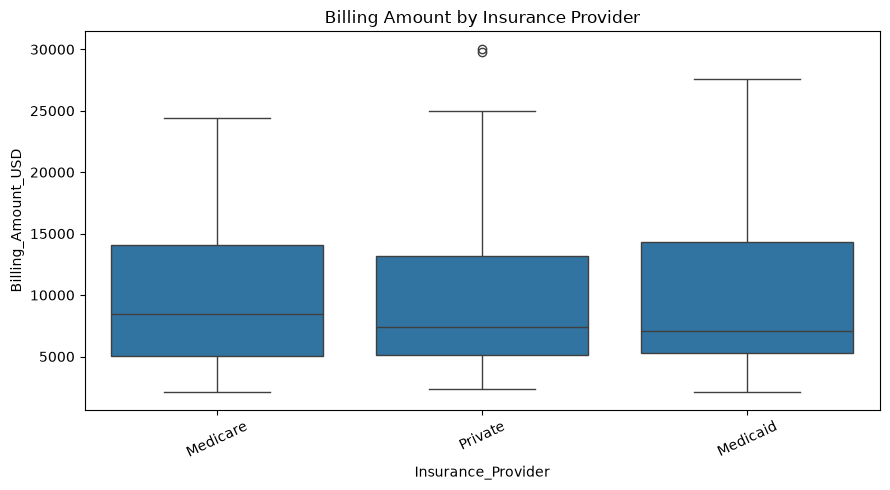

In [25]:

insurance_stats = df.groupby('Insurance_Provider').agg(
    Patient_Count=('Patient_ID', 'count'),
    Average_Billing=('Billing_Amount_USD', 'mean'),
    Median_Billing=('Billing_Amount_USD', 'median'),
    Average_Stay=('Length_of_Stay_Days', 'mean')
)

display(insurance_stats.round(2))

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Insurance_Provider',
    y='Billing_Amount_USD'
)

plt.title('Billing Amount by Insurance Provider')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

Missing values in Medical Condition were investigated to determine whether records with missing information differ from complete records. Identifying such patterns helps guide imputation decisions and assess potential data-quality concerns

,Count,Percentage
ICU_Admission,,
0,216,86.4
1,34,13.6


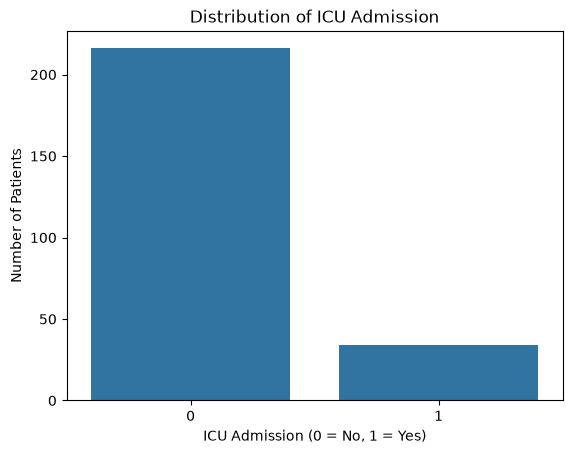

In [26]:

target_counts = df['ICU_Admission'].value_counts().sort_index()
target_percentages = df['ICU_Admission'].value_counts(
    normalize=True
).sort_index() * 100

target_summary = pd.DataFrame({
    'Count': target_counts,
    'Percentage': target_percentages
})

display(target_summary.round(2))

sns.countplot(data=df, x='ICU_Admission')
plt.title('Distribution of ICU Admission')
plt.xlabel('ICU Admission (0 = No, 1 = Yes)')
plt.ylabel('Number of Patients')
plt.show()

The target variable is imbalanced, with substantially more patients not admitted to the ICU than patients admitted. Therefore, accuracy alone may be misleading when evaluating a classification model. Precision, recall, F1-score, and the confusion matrix should also be considered

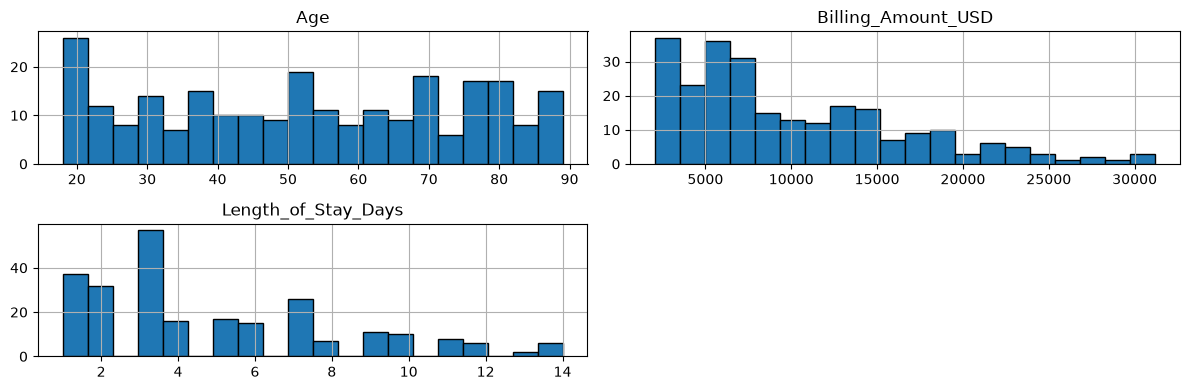

In [15]:
numerical_cols = [
    "Age",
    "Billing_Amount_USD",
    "Length_of_Stay_Days"
]

df[numerical_cols].hist(
    bins=20,
    figsize=(12, 4),
    edgecolor="black"
)

plt.tight_layout()
plt.show()

1. Age: The mean is 52.7 years, and the median is 52 years. Since they are close to each other, the age distribution appears approximately symmetric.

2. Billing_Amount_USD: The mean is greater than the median, indicating a right-skewed distribution.

3. Length_of_Stay_Days: The mean is 4.87 days, while the median is 3 days, also indicating a right-skewed distribution.

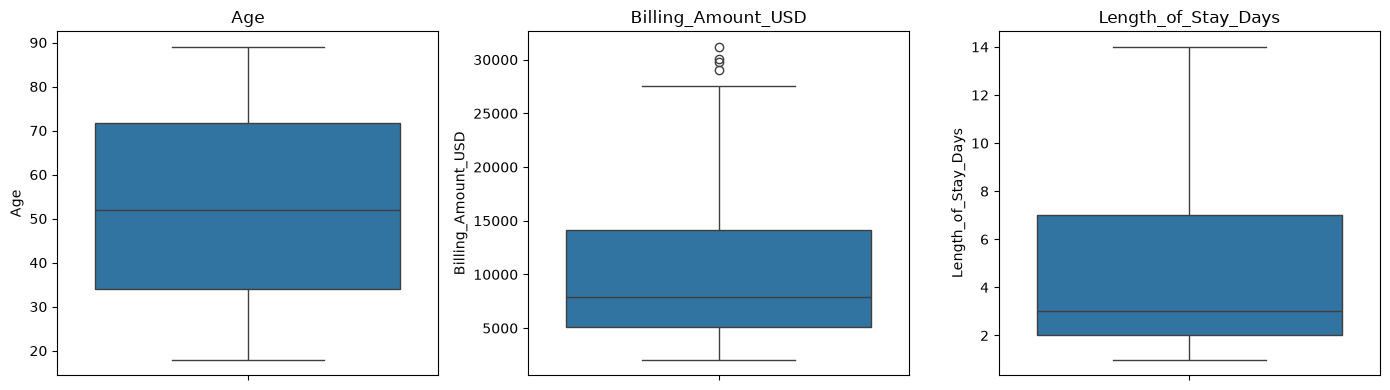

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, col in zip(axes, numerical_cols):
    sns.boxplot(data=df, y=col, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

    Gender: 138 Female and 112 Male patients.

    Severity: 108 Low, 87 Medium, and 55 High severity cases.

    ICU Admission: 216 patients were not admitted to the ICU (No), while 34 patients were admitted (Yes).

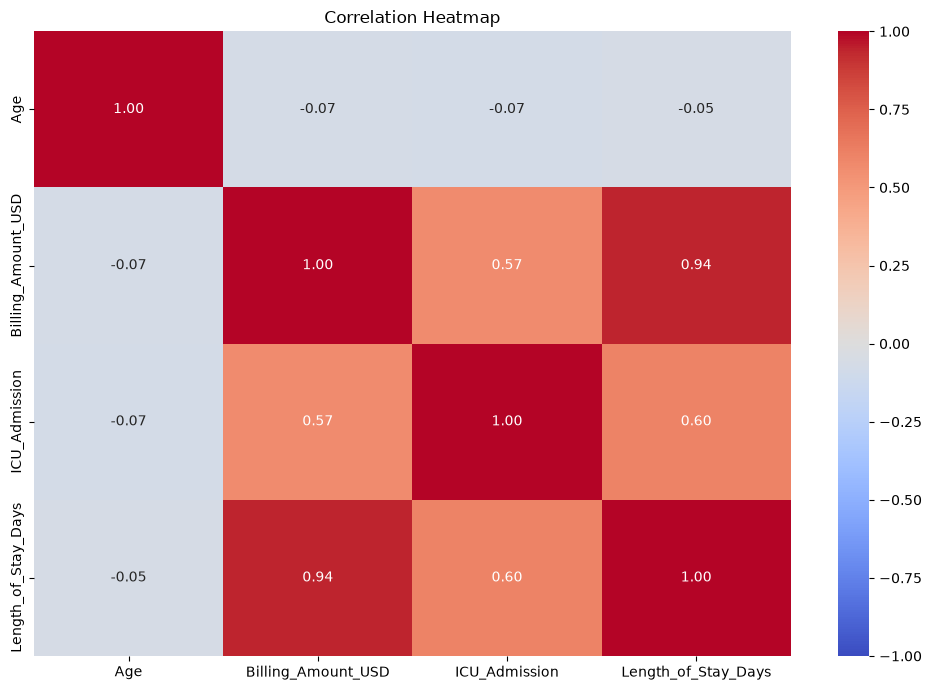

In [17]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

    Billing_Amount_USD and Length_of_Stay_Days: A very strong positive correlation of 0.94 was observed.

    ICU_Admission and Length_of_Stay_Days: A moderate positive correlation of approximately 0.60.

    ICU_Admission and Billing_Amount_USD: A moderate positive correlation of approximately 0.5

,Severity,ICU_Percentage
0,High,61.818182
1,Low,0.000000
2,Medium,0.000000


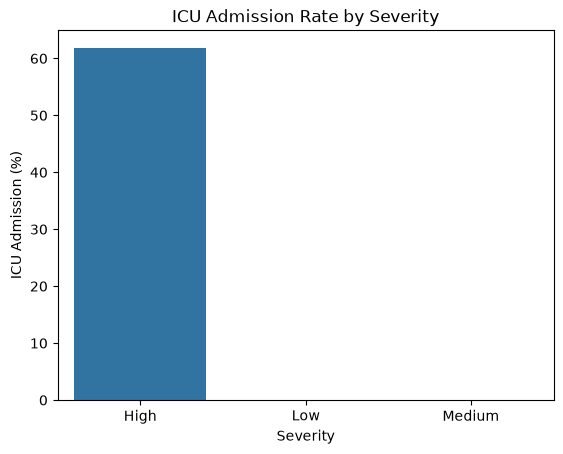

In [18]:
icu_rate = (
    df.groupby("Severity", observed=True)["ICU_Admission"]
    .mean()
    .mul(100)
    .reset_index(name="ICU_Percentage")
)

display(icu_rate)

sns.barplot(
    data=icu_rate,
    x="Severity",
    y="ICU_Percentage"
)

plt.title("ICU Admission Rate by Severity")
plt.ylabel("ICU Admission (%)")
plt.show()

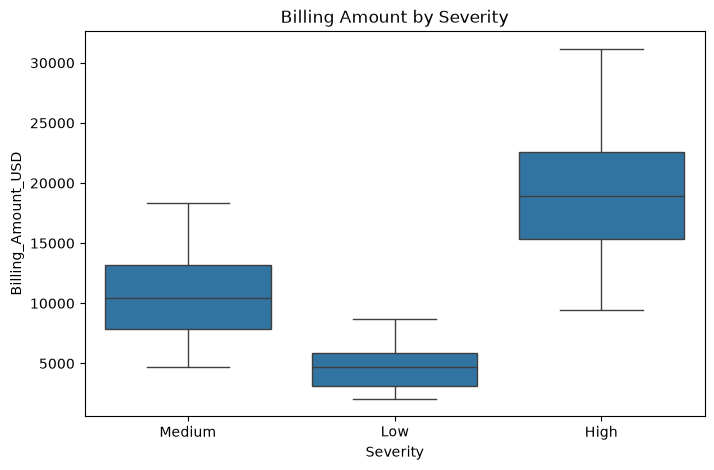

In [19]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Severity",
    y="Billing_Amount_USD"
)

plt.title("Billing Amount by Severity")
plt.show()

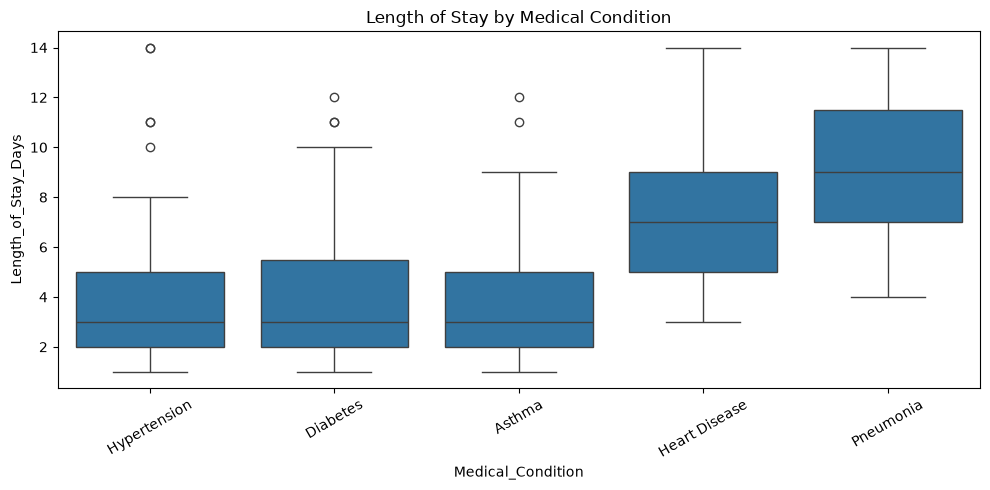

In [20]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Medical_Condition",
    y="Length_of_Stay_Days"
)

plt.title("Length of Stay by Medical Condition")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## EDA Summary and Key Findings

The exploratory data analysis was conducted to understand the hospital dataset's structure, quality, distributions, and relationships between variables.

- **Data Quality:** Missing values were identified in Medical Condition and Insurance Provider. These values should be investigated and handled appropriately before model training.
- **Numerical Features:** Age is approximately symmetric, while Billing Amount and Length of Stay show right-skewed distributions.
- **Categorical Features:** The dataset contains different genders, medical conditions, severity levels, insurance providers, and ICU admission outcomes.
- **Feature Relationships:** Billing Amount and Length of Stay have a strong positive correlation. ICU Admission also shows positive correlations with billing amount and length of stay.
- **Group Comparisons:** Comparing medical conditions, severity levels, age groups, and insurance providers can reveal differences in patient characteristics and hospital resource use.
- **Target Imbalance:** ICU admissions are less frequent than non-admissions, so multiple evaluation metrics will be needed when building a classification model.

### Conclusion

The EDA provides a foundation for preprocessing and Decision Tree modeling. Before training, missing values must be handled, categorical variables must be encoded, and the prediction target and timing of feature availability must be clearly defined. Potential data leakage should be checked before evaluating model performance.